# 3. Association rules with FP-Growth

Which combinations of airline, airport, route, day and time go together with late or on-time departures? Association-rule mining finds frequent combinations without a model: each departure is a "basket" of items such as `airline=آتا`, `time=Evening` and `delay=Late`, and FP-Growth finds the itemsets that occur often, from which rules like *{airline=X, time=Evening} → delay=Late* follow.

This complements the model: rules are readable and show interactions, but they describe co-occurrence in three weeks of data, not causes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import nbutils
from nbutils import BLUE, GREEN, GREY, ORANGE, RED

nbutils.setup()

In [2]:
from mlxtend.frequent_patterns import association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

from aeroscrape.data.clean import select_training_rows
from aeroscrape.features.build import add_calendar_features

flights, _ = nbutils.load_flights()
departures = add_calendar_features(select_training_rows(flights))
departures["delay_class"] = pd.cut(departures["delay_minutes"], [-np.inf, 15, 60, np.inf], labels=["On time", "Late", "Very late"]).astype(str)
departures["delay_class"].value_counts(normalize=True).round(3)

Ignoring 3 implausible delays outside [-60, 720] min


delay_class
Late         0.453
On time      0.413
Very late    0.133
Name: proportion, dtype: float64

## Transactions

Each departure becomes a set of `attribute=value` items. Rare values (fewer than 30 departures) are left out, so rules stay about patterns with enough support to mean something.

In [3]:
ATTRIBUTES = {
    "airline": "airline",
    "airport": "from",
    "destination_or_origin": "to",
    "scheduled_time_of_day": "time",
    "scheduled_day_of_week": "day",
    "delay_class": "delay",
}
items = pd.DataFrame({short: column.astype(str) for column, short in ATTRIBUTES.items() for column in [departures[column]]})
for short in items:
    counts = items[short].value_counts()
    items[short] = items[short].where(items[short].map(counts) >= 30)
transactions = [[f"{k}={v}" for k, v in row.items() if isinstance(v, str)] for row in items.to_dict("records")]
encoder = TransactionEncoder()
baskets = pd.DataFrame(encoder.fit(transactions).transform(transactions), columns=encoder.columns_)
print(f"{len(baskets):,} transactions, {baskets.shape[1]} distinct items, {baskets.sum(axis=1).mean():.1f} items each")

3,574 transactions, 78 distinct items, 5.9 items each


## Frequent itemsets

In [4]:
itemsets = fpgrowth(baskets, min_support=0.02, use_colnames=True)
itemsets["size"] = itemsets["itemsets"].map(len)
print(f"{len(itemsets):,} itemsets with support of at least 2%")
itemsets[itemsets["size"] >= 2].sort_values("support", ascending=False).head(12).assign(itemsets=lambda d: d["itemsets"].map(lambda s: ", ".join(sorted(s))))

315 itemsets with support of at least 2%


,support,itemsets,size
133,0.309,"delay=Late, from=فرودگاه مهرآباد",2
166,0.265,"from=فرودگاه مهرآباد, time=Morning",2
159,0.203,"delay=On time, from=فرودگاه مهرآباد",2
222,0.156,"from=فرودگاه مهرآباد, time=Evening",2
168,0.152,"delay=Late, time=Morning",2
170,0.143,"delay=Late, from=فرودگاه مهرآباد, time=Morning",3
52,0.134,"from=فرودگاه مهرآباد, to=مشهد",2
223,0.130,"delay=Late, time=Evening",2
224,0.127,"delay=On time, time=Evening",2
205,0.119,"delay=On time, to=تهران",2


## Rules that predict the delay class

Only rules whose consequent is the delay class are of interest. **Confidence** is the share of matching departures that had that outcome; **lift** compares it with the outcome's overall share (lift 1.3 = 30% more likely than average).

In [5]:
rules = association_rules(itemsets, metric="lift", min_threshold=1.1)
delay_rules = rules[rules["consequents"].map(lambda c: len(c) == 1 and next(iter(c)).startswith("delay="))].copy()
delay_rules["rule"] = delay_rules["antecedents"].map(lambda a: " + ".join(sorted(a))) + "  →  " + delay_rules["consequents"].map(lambda c: next(iter(c)))
delay_rules["departures"] = (delay_rules["support"] * len(baskets)).round().astype(int)
columns = ["rule", "departures", "support", "confidence", "lift"]
late = delay_rules[delay_rules["consequents"].map(lambda c: "Late" in next(iter(c)))].sort_values("lift", ascending=False)
late[columns].head(12).round(3)

,rule,departures,support,confidence,lift
46,from=فرودگاه مهرآباد + time=Evening + to=مشهد → delay=Late,74,0.021,0.632,1.395
247,airline=زاگرس → delay=Late,95,0.027,0.629,1.388
136,airline=آتا + from=فرودگاه مهرآباد + time=Morning → delay=Late,81,0.023,0.623,1.375
240,from=فرودگاه مهرآباد + to=اهواز → delay=Late,88,0.025,0.607,1.339
134,airline=آتا + time=Morning → delay=Late,82,0.023,0.603,1.330
502,day=Tuesday + from=فرودگاه مهرآباد + time=Morning → delay=Late,73,0.020,0.593,1.309
76,day=Thursday + from=فرودگاه مهرآباد + time=Morning → delay=Late,110,0.031,0.582,1.284
490,day=Tuesday + from=فرودگاه مهرآباد → delay=Late,153,0.043,0.573,1.264
192,from=فرودگاه مهرآباد + to=شیراز → delay=Late,96,0.027,0.565,1.246
70,day=Thursday + time=Morning → delay=Late,119,0.033,0.561,1.238


In [6]:
on_time = delay_rules[delay_rules["consequents"].map(lambda c: next(iter(c)) == "delay=On time")].sort_values("lift", ascending=False)
on_time[columns].head(10).round(3)

,rule,departures,support,confidence,lift
219,airline=ماهان + to=تهران → delay=On time,95,0.027,0.812,1.965
225,airline=ماهان + time=Afternoon → delay=On time,78,0.022,0.716,1.732
231,airline=ماهان + time=Evening → delay=On time,88,0.025,0.677,1.638
201,airline=ماهان → delay=On time,249,0.070,0.654,1.581
337,time=Afternoon + to=تهران → delay=On time,140,0.039,0.619,1.499
182,from=فرودگاه اصفهان → delay=On time,78,0.022,0.578,1.398
343,time=Evening + to=تهران → delay=On time,162,0.045,0.564,1.366
91,day=Thursday + to=تهران → delay=On time,72,0.020,0.550,1.330
331,to=تهران → delay=On time,424,0.119,0.548,1.326
350,from=فرودگاه شیراز → delay=On time,101,0.028,0.534,1.293


## Support, confidence and lift together

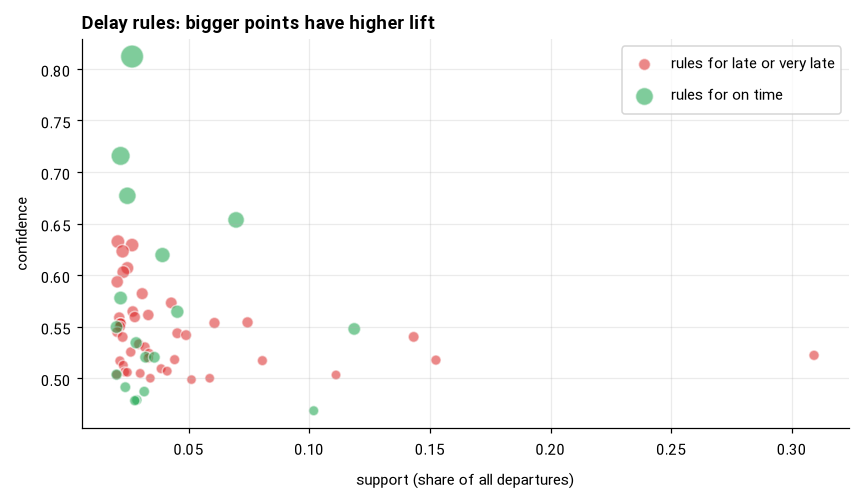

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for name, group, color in [("rules for late or very late", late, RED), ("rules for on time", on_time, GREEN)]:
    ax.scatter(group["support"], group["confidence"], s=group["lift"] ** 3 * 30, alpha=0.55, color=color, label=name, edgecolor="white")
ax.set_xlabel("support (share of all departures)")
ax.set_ylabel("confidence")
ax.set_title("Delay rules: bigger points have higher lift")
ax.legend()

## Reading the rules

- Late rules are about the airlines with the highest delay rates (زاگرس, آتا, in the morning) and about Mehrabad: its morning bank, its evening flights to Mashhad, its routes to Ahvaz and Shiraz. Single airlines and combinations both appear, the kind of interaction a model has to learn.
- On-time rules are dominated by ماهان (81% on time on flights to Tehran, against 41% overall) and by flights into Tehran and out of Isfahan and Shiraz.
- Lifts are modest: at most 1.4 for late rules (63% late where 45% is typical) and 2.0 for the best on-time rule. No combination of these attributes makes a delay certain, which matches the model's modest gains over the airline baseline.
- Rules describe three weeks of 2025 data. They are a way to understand the data and sanity-check the model's explanations (notebook 4), not predictions; their lift is measured on the same data they were mined from.

The pipeline runs the same mining in the training DAG (`association_mining` task, `aeroscrape.analysis.association`) and stores the rules with each run.